In [1]:
import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from collections import Counter
from itertools import combinations, permutations

1.a

In [2]:
def deterministic_lotka_volterra(p_1_o, p_2_o, alpha, beta, gamma, delta, t_max, dt):
    """
    simulates the L-V predator-prey model using Euler's integration
    follows methods from sir in class 13 notebook and sayama scripts

    Parameters:
    p_1_o: Initial prey population.
    p_2_o: Initial predator population.
    alpha: Prey reproduction rate.
    beta: Predation rate.
    gamma: Predator death rate.
    delta: Predator growth rate given food.
    t_max: Final time of the simulation (simulation runs from t=0 to t=t_max).
    dt: Time step size.

    The populations evolve according to:
        - dp_1/dt = alpha * p_1 - beta * p_1 * p_2
        - dp_2/dt = delta * p_1 * p_2 - gamma * p_2
    """

    # Number of steps needed to go from t=0 to t=t_max
    n_steps = int(round(t_max / dt))

    # arrays for storing time and populations at each time step
    t = np.linspace(0, t_max, n_steps + 1)
    p_1 = np.zeros(n_steps + 1)
    p_2 = np.zeros(n_steps + 1)
    p_1[0] = p_1_o
    p_2[0] = p_2_o

    # Euler update taken from Sayama, predator-prey-continuous.py, see .tex for cite
    # with variables renamed: x -> p_1, y -> p_2, a/b/c/d -> alpha/beta/gamma/delta, Dt -> dt.
    for i in range(n_steps):
        # Prey: reproduction minus predation
        p_1[i+1] = p_1[i] + (alpha * p_1[i] - beta * p_1[i] * p_2[i]) * dt

        # Predators: growth from eating prey minus death
        p_2[i+1] = p_2[i] + (delta * p_1[i] * p_2[i] - gamma * p_2[i]) * dt

    return t, p_1, p_2

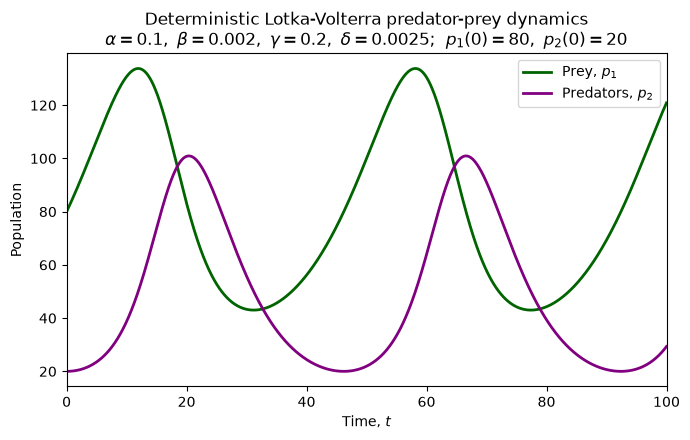

In [3]:
alpha, beta, gamma, delta = 0.1, 0.002, 0.2, 0.0025
p_1_o, p_2_o = 80, 20 # initial prey, predators
t_max, dt = 100, 0.0001

t, p_1, p_2 = deterministic_lotka_volterra(p_1_o, p_2_o, alpha, beta, gamma, delta, t_max, dt)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(t, p_1, linewidth=2, color="darkgreen", label=r"Prey, $p_1$")
ax.plot(t, p_2, linewidth=2, color="purple", label=r"Predators, $p_2$")
ax.set_xlabel(r"Time, $t$")
ax.set_ylabel("Population")
ax.set_title("Deterministic Lotka-Volterra predator-prey dynamics\n"
             rf"$\alpha={alpha},\ \beta={beta},\ \gamma={gamma},\ \delta={delta}$;  "
             rf"$p_1(0)={p_1_o},\ p_2(0)={p_2_o}$")
ax.set_xlim(0, t_max)
ax.legend()
fig.tight_layout()
fig.savefig("figures/q1a_lotka_volterra.png", dpi=300)
plt.show()

1.b

Total extinction: p_1 in [0.00134, 80], p_2 in [4.58e-08, 20], final (p_1, p_2) = (0.00134, 4.58e-08)
Predator extinction, unbounded prey growth: p_1 in [80, 1.44e+06], p_2 in [4.12e-08, 20], final (p_1, p_2) = (1.44e+06, 4.12e-08)
Steady coexistence: p_1 in [80, 80], p_2 in [20, 20], final (p_1, p_2) = (80, 20)
Neutral cycles (1.a rates): p_1 in [43, 134], p_2 in [20, 101], final (p_1, p_2) = (121, 29.3)


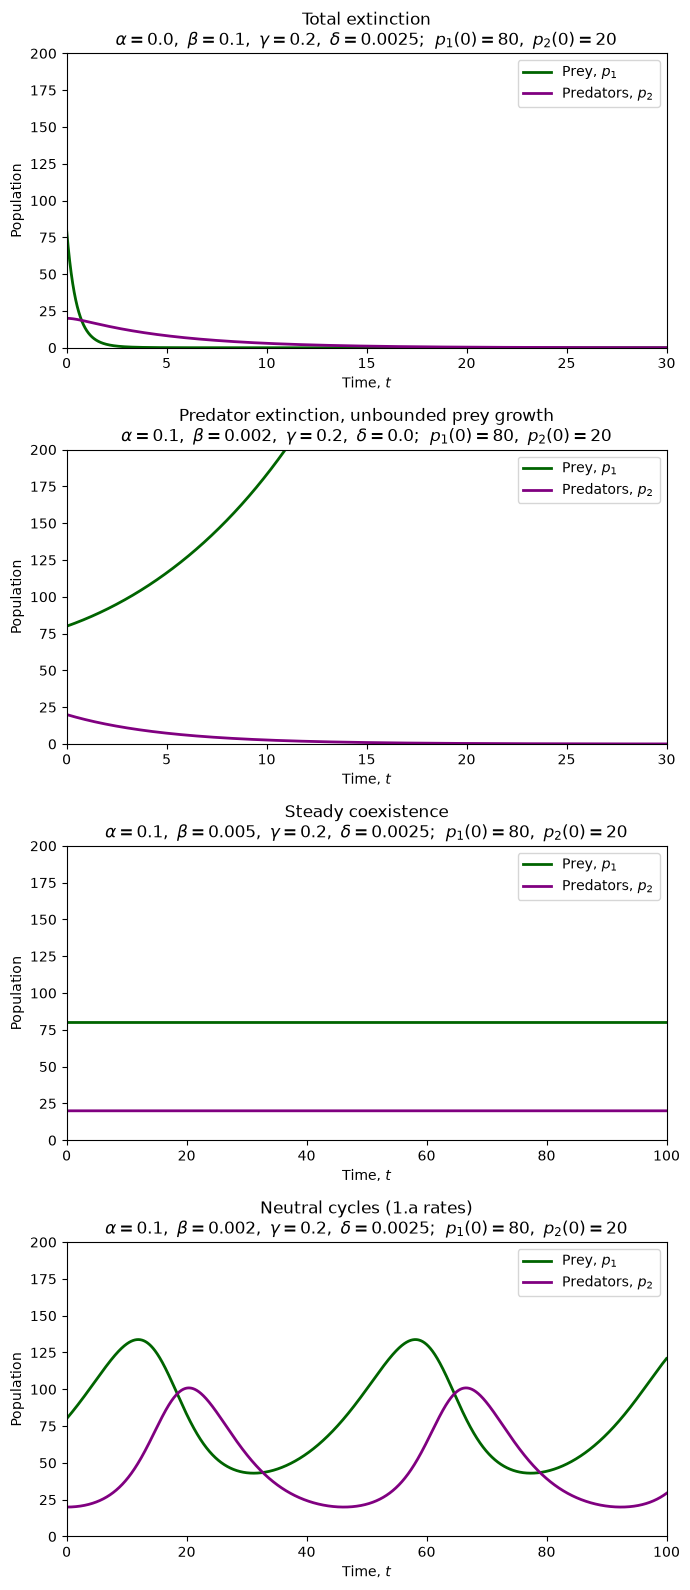

In [4]:
# 1.b same starting populations as 1.a, only rates change
p_1_o, p_2_o = 80, 20 
t_max, dt = 100, 0.0001

# title, alpha, beta, gamma, delta, x-axis limit
cases = [
    ("Total extinction", 0.0, 0.1, 0.2, 0.0025, 30),
    ("Predator extinction, unbounded prey growth", 0.1, 0.002, 0.2, 0.0, 30),
    ("Steady coexistence", 0.1, 0.005, 0.2, 0.0025, 100),
    ("Neutral cycles (1.a rates)", 0.1, 0.002, 0.2, 0.0025, 100),
]

fig, axes = plt.subplots(4, 1, figsize=(7, 16))
for ax, (name, alpha, beta, gamma, delta, x_max) in zip(axes, cases):
    t, p_1, p_2 = deterministic_lotka_volterra(p_1_o, p_2_o, alpha, beta, gamma, delta, t_max, dt)
    print(f"{name}: p_1 in [{p_1.min():.3g}, {p_1.max():.3g}], p_2 in [{p_2.min():.3g}, {p_2.max():.3g}], "
          f"final (p_1, p_2) = ({p_1[-1]:.3g}, {p_2[-1]:.3g})")

    ax.plot(t, p_1, linewidth=2, color="darkgreen", label=r"Prey, $p_1$")
    ax.plot(t, p_2, linewidth=2, color="purple", label=r"Predators, $p_2$")
    ax.set_xlabel(r"Time, $t$")
    ax.set_ylabel("Population")
    ax.set_title(f"{name}\n"
                 rf"$\alpha={alpha},\ \beta={beta},\ \gamma={gamma},\ \delta={delta}$;  "
                 rf"$p_1(0)={p_1_o},\ p_2(0)={p_2_o}$")
    ax.set_xlim(0, x_max)
    ax.set_ylim(0, 200)
    ax.legend()

fig.tight_layout()
fig.savefig("figures/q1b_outcomes.png", dpi=300)
plt.show()

p_1 in [50, 120], p_2 in [25.2, 87.5]


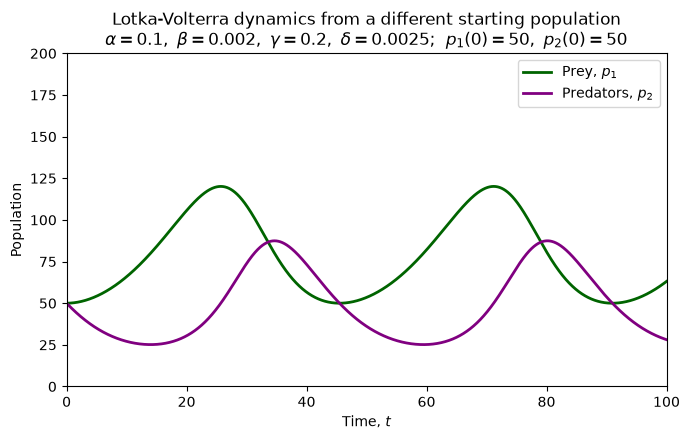

In [5]:
# example with a different starting population, back to the 1.a rates
alpha, beta, gamma, delta = 0.1, 0.002, 0.2, 0.0025
p_1_o, p_2_o = 50, 50 # initial prey, predators
t_max, dt = 100, 0.0001

t, p_1, p_2 = deterministic_lotka_volterra(p_1_o, p_2_o, alpha, beta, gamma, delta, t_max, dt)
print(f"p_1 in [{p_1.min():.3g}, {p_1.max():.3g}], p_2 in [{p_2.min():.3g}, {p_2.max():.3g}]")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(t, p_1, linewidth=2, color="darkgreen", label=r"Prey, $p_1$")
ax.plot(t, p_2, linewidth=2, color="purple", label=r"Predators, $p_2$")
ax.set_xlabel(r"Time, $t$")
ax.set_ylabel("Population")
ax.set_title("Lotka-Volterra dynamics from a different starting population\n"
             rf"$\alpha={alpha},\ \beta={beta},\ \gamma={gamma},\ \delta={delta}$;  "
             rf"$p_1(0)={p_1_o},\ p_2(0)={p_2_o}$")
ax.set_xlim(0, t_max)
ax.set_ylim(0, 200)
ax.legend()
fig.tight_layout()
fig.savefig("figures/q1b_varied_start.png", dpi=300)
plt.show()

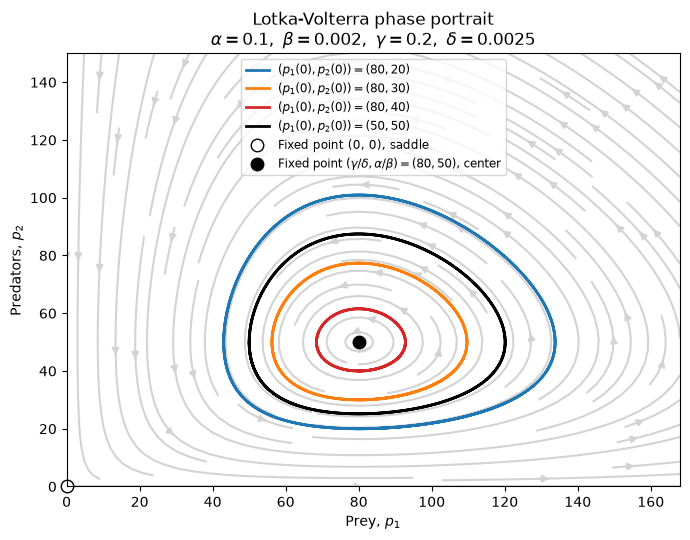

In [6]:
# phase portrait for the 1.a rates
alpha, beta, gamma, delta = 0.1, 0.002, 0.2, 0.0025
t_max, dt = 100, 0.0001

# vector field: meshgrid + streamplot taken from Sayama, phasespace-drawing-streamplot.py,
# with x -> p_1, y -> p_2 and the Lotka-Volterra right-hand sides
p_1_grid, p_2_grid = np.meshgrid(np.arange(0, 170, 2), np.arange(0, 152, 2))
p_1_dot = alpha * p_1_grid - beta * p_1_grid * p_2_grid
p_2_dot = delta * p_1_grid * p_2_grid - gamma * p_2_grid

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.streamplot(p_1_grid, p_2_grid, p_1_dot, p_2_dot, color="lightgray", density=1.2)

# orbits from several starting points, looping over initial conditions as in
# Sayama, phasespace-drawing.py 
starts = [(80, 20), (80, 30), (80, 40), (50, 50)]
colors = ["tab:blue", "tab:orange", "tab:red", "black"]
for (p_1_o, p_2_o), color in zip(starts, colors):
    t, p_1, p_2 = deterministic_lotka_volterra(p_1_o, p_2_o, alpha, beta, gamma, delta, t_max, dt)
    ax.plot(p_1, p_2, linewidth=2, color=color, label=rf"$(p_1(0), p_2(0)) = ({p_1_o}, {p_2_o})$")

# add in fixed points, saddles, etc
ax.plot(0, 0, "o", markersize=9, markerfacecolor="white", markeredgecolor="black", clip_on=False,
        label="Fixed point (0, 0), saddle")
ax.plot(gamma / delta, alpha / beta, "o", markersize=9, color="black",
        label=rf"Fixed point $(\gamma/\delta, \alpha/\beta) = ({gamma/delta:.0f}, {alpha/beta:.0f})$, center")

ax.set_xlabel(r"Prey, $p_1$")
ax.set_ylabel(r"Predators, $p_2$")
ax.set_title("Lotka-Volterra phase portrait\n"
             rf"$\alpha={alpha},\ \beta={beta},\ \gamma={gamma},\ \delta={delta}$")
ax.set_xlim(0, 168)
ax.set_ylim(0, 150)
ax.legend(fontsize="small")
fig.tight_layout()
fig.savefig("figures/q1b_phase_portrait.png", dpi=300)
plt.show()

1.c

In [7]:
def deterministic_epidemic_sirs(N, I_o, beta, mu, omega, t_max, dt):
    """
    simulates the SIRS model using Euler's integration
    follows deterministic_epidemic_sir from the class 13 notebook, with the
    omega * R return term (R -> S) added and a dt step like deterministic_lotka_volterra

    Parameters:
    N: Total population size (constant).
    I_o: Initial infected population (everyone else starts susceptible).
    beta: Transmission rate.
    mu: Recovery rate.
    omega: Rate of return from R to S (waning immunity).
    t_max: Final time of the simulation (simulation runs from t=0 to t=t_max).
    dt: Time step size.

    The compartments evolve according to:
        - dS/dt = -beta * S * I / N + omega * R
        - dI/dt =  beta * S * I / N - mu * I
        - dR/dt =  mu * I - omega * R
    """

    n_steps = int(round(t_max / dt))

    t = np.linspace(0, t_max, n_steps + 1)
    S = np.zeros(n_steps + 1)
    I = np.zeros(n_steps + 1)
    R = np.zeros(n_steps + 1)
    S[0] = N - I_o
    I[0] = I_o

    for i in range(n_steps):
        new_infections = beta * S[i] * I[i] / N
        S[i+1] = S[i] + (-new_infections + omega * R[i]) * dt
        I[i+1] = I[i] + (new_infections - mu * I[i]) * dt
        R[i+1] = R[i] + (mu * I[i] - omega * R[i]) * dt

    return t, S, I, R

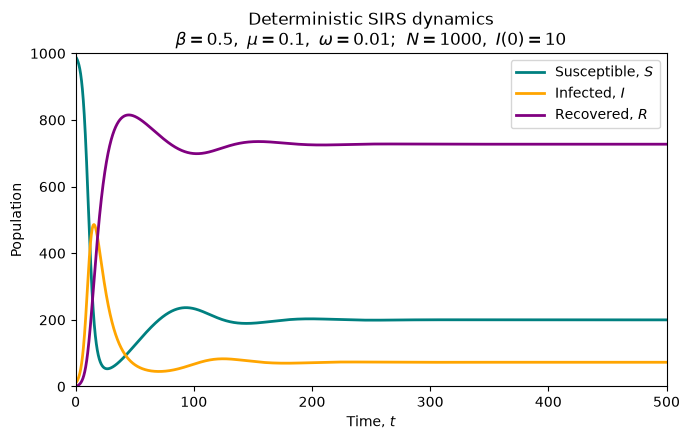

In [8]:
N, I_o = 1000, 10
beta, mu, omega = 0.5, 0.1, 0.01
t_max, dt = 500, 0.01

t, S, I, R = deterministic_epidemic_sirs(N, I_o, beta, mu, omega, t_max, dt)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(t, S, linewidth=2, color="teal", label=r"Susceptible, $S$")
ax.plot(t, I, linewidth=2, color="orange", label=r"Infected, $I$")
ax.plot(t, R, linewidth=2, color="purple", label=r"Recovered, $R$")
ax.set_xlabel(r"Time, $t$")
ax.set_ylabel("Population")
ax.set_title("Deterministic SIRS dynamics\n"
             rf"$\beta={beta},\ \mu={mu},\ \omega={omega}$;  $N={N},\ I(0)={I_o}$")
ax.set_xlim(0, t_max)
ax.set_ylim(0, N)
ax.legend()
fig.tight_layout()
fig.savefig("figures/q1c_sirs.png", dpi=300)
plt.show()

2.a

In [ ]:
# node states
EMPTY, PREY, PRED = 0, 1, 2


def initialize_lv_states(G, x, y, rng):
    """
    Assigns round(x*N) random nodes as prey, round(y*N) random nodes as predators,
    and leaves the rest empty. Returns a dict of nodes and states
    """
    nodes = list(G.nodes())
    N = len(nodes)
    n_prey, n_pred = round(x * N), round(y * N)
    if n_prey + n_pred > N:
        raise ValueError("prey + predators pop must be at most 1")

    # shuffle node positions, first n_prey become prey, next n_pred become predators
    order = rng.permutation(N)
    state = {node: EMPTY for node in nodes}
    for i in order[:n_prey]:
        state[nodes[i]] = PREY
    for i in order[n_prey:n_prey + n_pred]:
        state[nodes[i]] = PRED
    return state


def count_lv(state):
    # Returns the (prey, predators) counts for one state
    values = list(state.values())
    return (values.count(PREY), values.count(PRED))


def lv_step(G, state, alpha, beta, gamma, delta, rng):
    """
    Conflict rules found from debugging:
      - If two prey pick the same empty node, nodes are visited in index order, so the
        lower-indexed prey claims it and the higher-indexed prey loses its turn.
      - Birth before death: a prey that is eaten this step may still reproduce.
      - Eat before death: a predator that dies this step may still eat this step.
    The three kinds of change touch disjoint sets of nodes (births only fill nodes that
    were empty at t, predation only changes nodes that were prey at t, deaths only change
    nodes that were predators at t), so births into the same empty node are the only conflict.
    """
    next_state = dict(state)
    # empty nodes already filled by a birth this step
    claimed = set()  

    # G.nodes() order = node index order
    for node in G.nodes():  
        if state[node] == PREY:
            # reproduction: with probability alpha, pick a random empty neighbor (empty at time t)
            if rng.random() < alpha:
                empty_nbrs = [n for n in G.neighbors(node) if state[n] == EMPTY]
                if empty_nbrs:
                    # pick by integer index so tuple node labels work
                    target = empty_nbrs[rng.integers(len(empty_nbrs))]
                    # a lower-indexed prey already took it -> lose turn
                    if target not in claimed:  
                        claimed.add(target)
                        next_state[target] = PREY

            # predation: each neighboring predator independently gets a beta chance to eat this prey,
            # so P(eaten) = 1 - (1 - beta)^(number of predator neighbors). The prey is only eaten once,
            # however many predators succeed, so there is a single delta roll for the node
            n_pred_nbrs = sum(1 for n in G.neighbors(node) if state[n] == PRED)
            eaten = any(rng.random() < beta for _ in range(n_pred_nbrs))
            if eaten:
                # with probability delta the vertex becomes a new predator, otherwise empty
                next_state[node] = PRED if rng.random() < delta else EMPTY

        elif state[node] == PRED:
            # with probability gamma the predator dies and the vertex becomes empty
            if rng.random() < gamma:
                next_state[node] = EMPTY

    return next_state


def graphLotkeVolterra(G, x, y, alpha, beta, gamma, delta, T, seed=None):
    """
    Parameters:
    G: networkx graph 
    x: Fraction of nodes that start as prey
    y: Fraction of nodes that start as predators (the rest start empty)
    alpha: Probability a prey reproduces into a random empty neighbor each step.
    beta: Probability each neighboring predator eats a given prey each step.
    gamma: Probability a predator dies each step.
    delta: Probability an eaten prey's node becomes a predator instead of empty.
    T: Number of time steps.

    Returns:
    list of T + 1 tuples (prey, predators)
    """
    rng = np.random.default_rng(seed)
    state = initialize_lv_states(G, x, y, rng)
    counts = [count_lv(state)]
    for t in range(T):
        state = lv_step(G, state, alpha, beta, gamma, delta, rng)
        counts.append(count_lv(state))
    return counts

In [ ]:
def snapshot_times(T):
    # t = 1..5, then 5 more times spread equally over the rest of the run, ending at T.
    if T < 10:
        raise ValueError("T must be at least 10 for 10 distinct snapshot times")
    first = list(range(1, 6))
    rest = np.linspace(5, T, 6)[1:].round().astype(int).tolist()
    return first + rest


def plot_lv_snapshots(G, x, y, alpha, beta, gamma, delta, T, seed, pos=None,
                      style="network", n_cols=20, title="Lotka-Volterra on a network"):
    # style = "network": draw nodes and edges with a fixed layout (small graphs like karate club)
    # style = "lattice": grid_2d_graph only, each node drawn as one cell at its (i, j) lattice position
    # style = "array":   nodes placed in index order on a fixed n_cols-wide array
    times = snapshot_times(T)
    rng = np.random.default_rng(seed)
    state = initialize_lv_states(G, x, y, rng)
    snapshots = {}
    for t in range(1, T + 1):
        state = lv_step(G, state, alpha, beta, gamma, delta, rng)
        if t in times:
            snapshots[t] = dict(state)

    # one fixed layout for every panel, so each node stays in the same place
    if style == "network" and pos is None:
        pos = nx.spring_layout(G, seed=seed)
    colors = {EMPTY: "gray", PREY: "blue", PRED: "red"}  
    # colormap for the image styles: state 0 -> gray, 1 -> blue, 2 -> red
    state_cmap = matplotlib.colors.ListedColormap([colors[EMPTY], colors[PREY], colors[PRED]])

    def state_image(s):
        # turns one state dict into a 2D array of states for imshow
        if style == "lattice":
            n_rows = 1 + max(i for i, j in G.nodes())
            n_cols_lat = 1 + max(j for i, j in G.nodes())
            img = np.zeros((n_rows, n_cols_lat))
            for (i, j), v in s.items():
                img[i, j] = v
            return img
        # "array": node k (in G.nodes() order) goes to row k // n_cols, column k % n_cols
        nodes = list(G.nodes())
        n_rows = int(np.ceil(len(nodes) / n_cols))
        # fill a last row with nan if not full
        img = np.full(n_rows * n_cols, np.nan)  
        img[:len(nodes)] = [s[n] for n in nodes]
        return img.reshape(n_rows, n_cols)

    figsize = {"network": (8, 16), "lattice": (8, 20), "array": (6, 30)}[style]
    fig, axes = plt.subplots(5, 2, figsize=figsize)
    # fill column by column: t = 1..5 down the left column, the spread-out times down the right
    for ax, t in zip(axes.T.flat, times):
        s = snapshots[t]
        n_prey, n_pred = count_lv(s)
        if style == "network":
            nx.draw_networkx_edges(G, pos, ax=ax, edge_color="0.7")
            nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[colors[s[n]] for n in G.nodes()],
                                   node_size=60, edgecolors="black", linewidths=0.5)
        else:
            ax.imshow(state_image(s), cmap=state_cmap, vmin=-0.5, vmax=2.5, interpolation="nearest")
        # array panels are narrow, so put their titles on two lines
        sep = "\n" if style == "array" else ": "
        ax.set_title(f"t = {t}{sep}{n_prey} prey, {n_pred} predators")
        ax.set_axis_off()

    # one legend for the whole figure
    handles = [plt.Line2D([0], [0], marker="o", linestyle="", markerfacecolor=c, markeredgecolor="black",
                          markersize=8, label=name)
               for name, c in [("Prey", "blue"), ("Predator", "red"), ("Empty", "gray")]]
    fig.legend(handles=handles, loc="lower center", ncol=3)
    fig.suptitle(f"{title}\n"
                 rf"$\alpha={alpha},\ \beta={beta},\ \gamma={gamma},\ \delta={delta}$;  "
                 rf"$x={x},\ y={y}$, seed $={seed}$")
    # leave room at the top for the two-line on the taller image figures
    fig.tight_layout(rect=(0, 0.03, 1, 1 if style == "network" else 0.97))
    return fig


def plot_lv_populations(counts, N, alpha, beta, gamma, delta, x, y, seed, title="Lotka-Volterra on a network"):
    t = np.arange(len(counts))
    prey = np.array([c[0] for c in counts]) / N * 100
    pred = np.array([c[1] for c in counts]) / N * 100
    empty = 100 - prey - pred  # every node is prey, predator, or empty

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(t, prey, linewidth=2, color="blue", label="Prey")
    ax.plot(t, pred, linewidth=2, color="red", label="Predators")
    ax.plot(t, empty, linewidth=2, color="gray", label="Empty")
    ax.set_xlabel(r"Time step, $t$")
    ax.set_ylabel(f"Percent of nodes (N = {N})")
    ax.set_title(f"{title}\n"
                 rf"$\alpha={alpha},\ \beta={beta},\ \gamma={gamma},\ \delta={delta}$;  "
                 rf"$x={x},\ y={y}$, seed $={seed}$")
    ax.set_xlim(0, t[-1])
    ax.set_ylim(0, 100)
    ax.legend()
    fig.tight_layout()
    return fig

first 6 (prey, predators): [(14, 3), (19, 3), (22, 3), (25, 2), (30, 2), (31, 3)]
at snapshot times: [(1, (19, 3)), (2, (22, 3)), (3, (25, 2)), (4, (30, 2)), (5, (31, 3)), (24, (14, 11)), (43, (9, 13)), (62, (12, 11)), (81, (15, 11)), (100, (8, 8))]


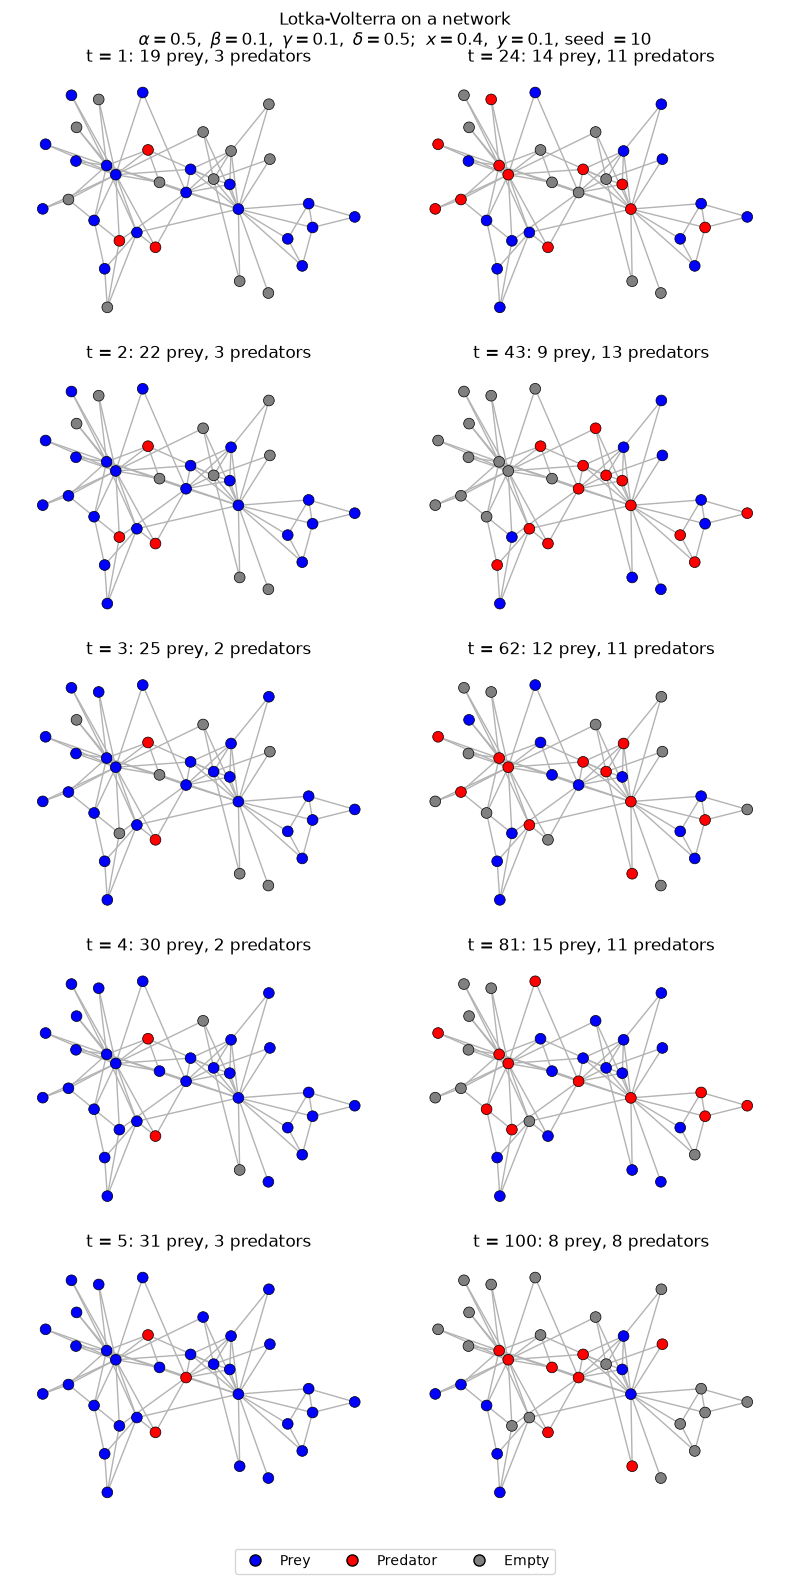

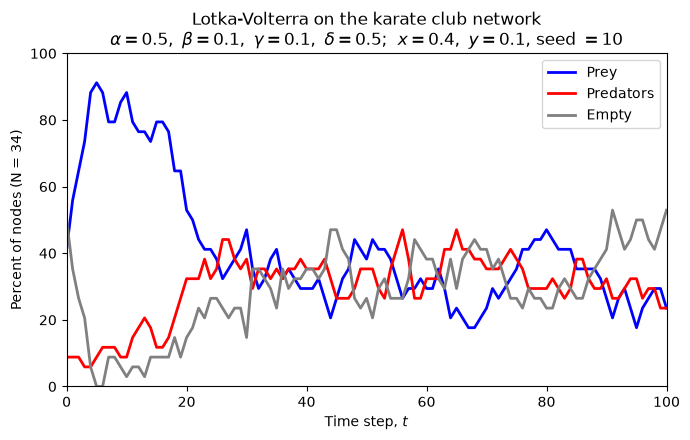

In [11]:
# Karate club example: 0.4 prey, 0.1 predators, as in the question matter
G_kc = nx.karate_club_graph()
x, y = 0.4, 0.1
alpha, beta, gamma, delta = 0.5, 0.1, 0.1, 0.5
T, seed = 100, 10

counts = graphLotkeVolterra(G_kc, x, y, alpha, beta, gamma, delta, T, seed=seed)
print("first 6 (prey, predators):", counts[:6])
print("at snapshot times:", [(t, counts[t]) for t in snapshot_times(T)])

fig = plot_lv_snapshots(G_kc, x, y, alpha, beta, gamma, delta, T, seed)
fig.savefig("figures/q2a_karate_snapshots.png", dpi=300)
plt.show()

fig = plot_lv_populations(counts, G_kc.number_of_nodes(), alpha, beta, gamma, delta, x, y, seed,
                          title="Lotka-Volterra on the karate club network")
fig.savefig("figures/q2a_karate_populations.png", dpi=300)
plt.show()

2.b

2D grid (100 x 100): N = 10000, final prey = 73.1%, final predators = 20.2%, predators extinct at t = None


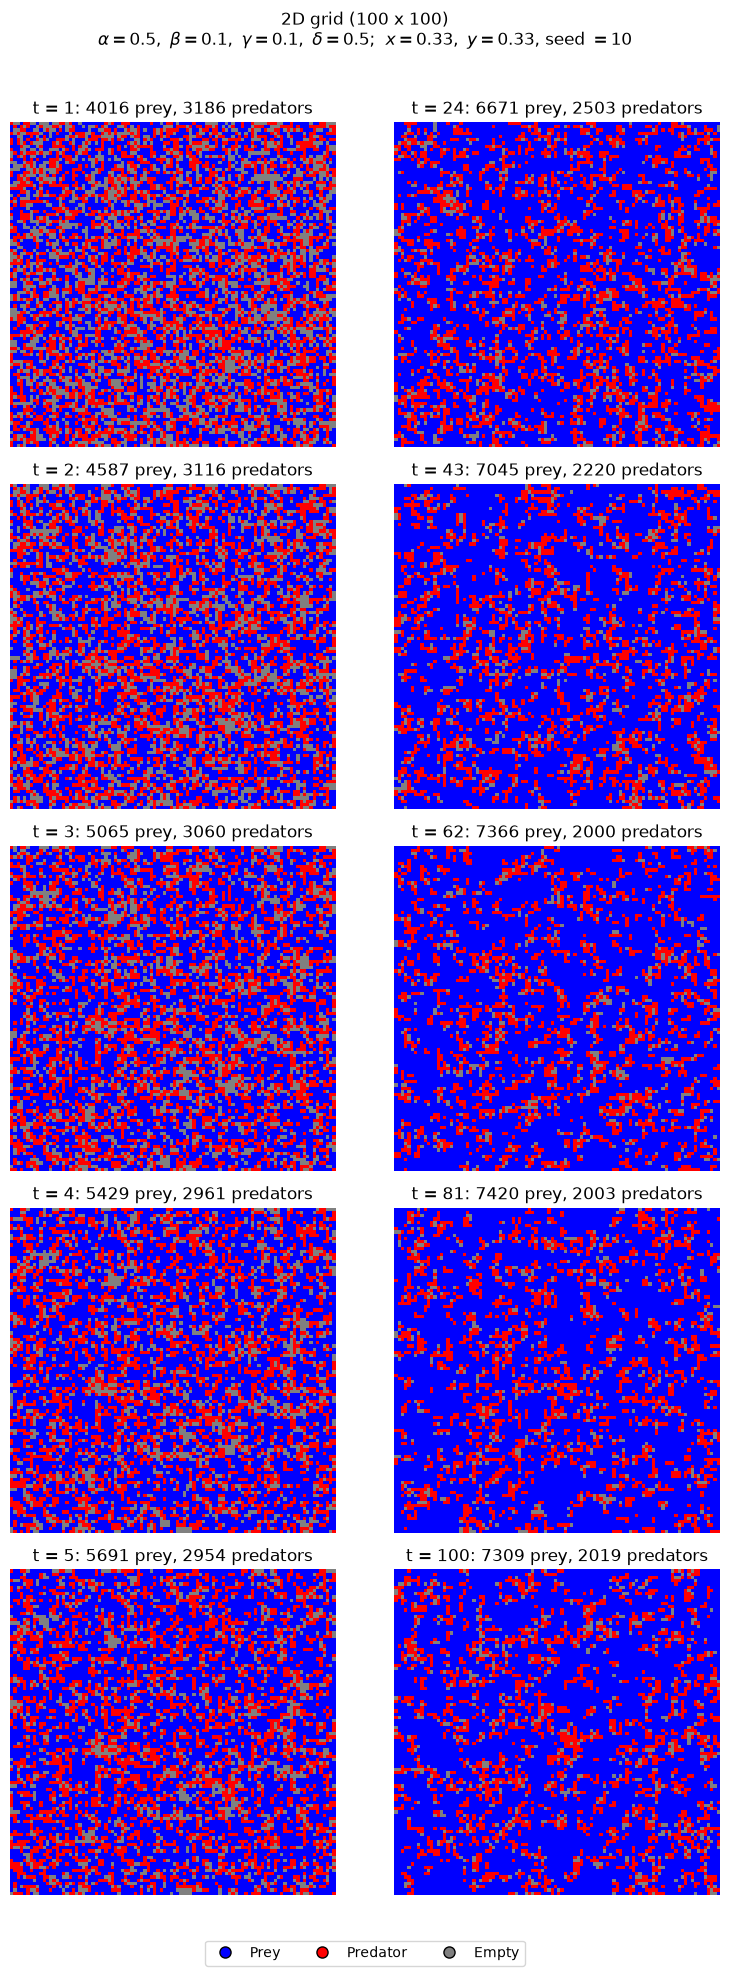

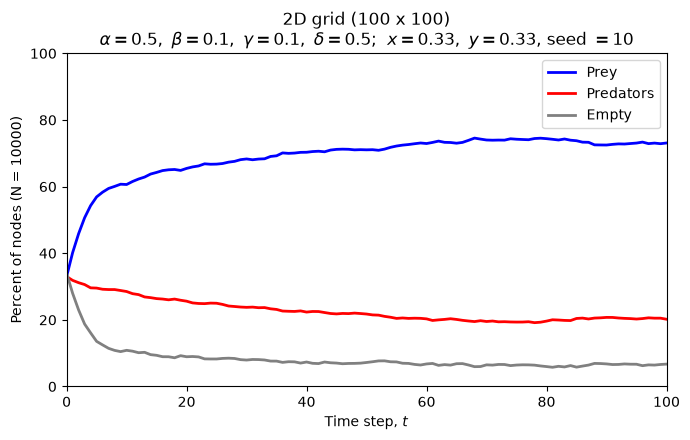

Erdos-Renyi (N = 1000, p = 0.05): N = 1000, final prey = 0.0%, final predators = 0.0%, predators extinct at t = 63


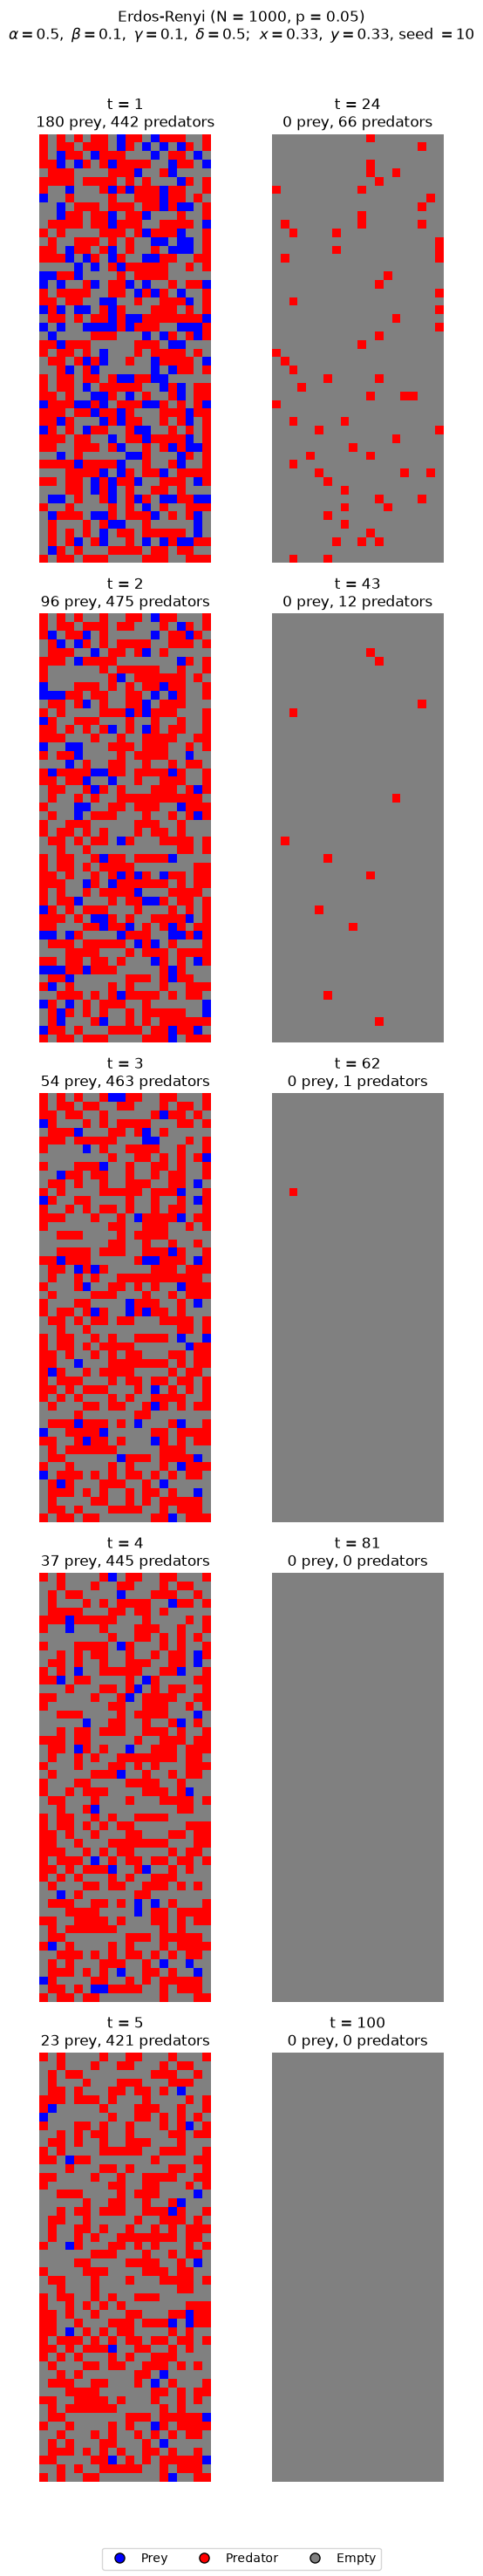

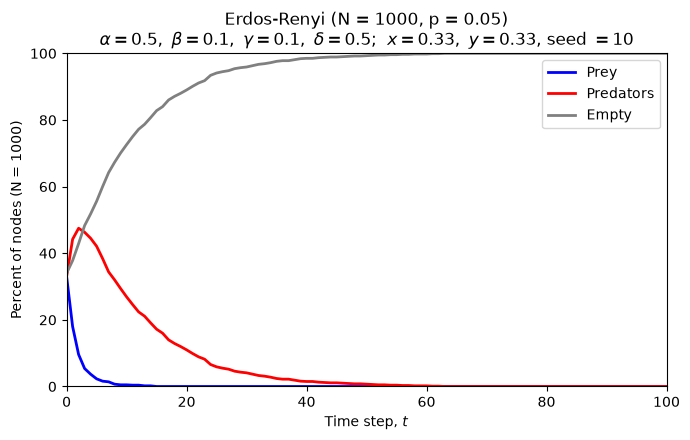

Barabasi-Albert (N = 1000, m = 2): N = 1000, final prey = 48.8%, final predators = 25.1%, predators extinct at t = None


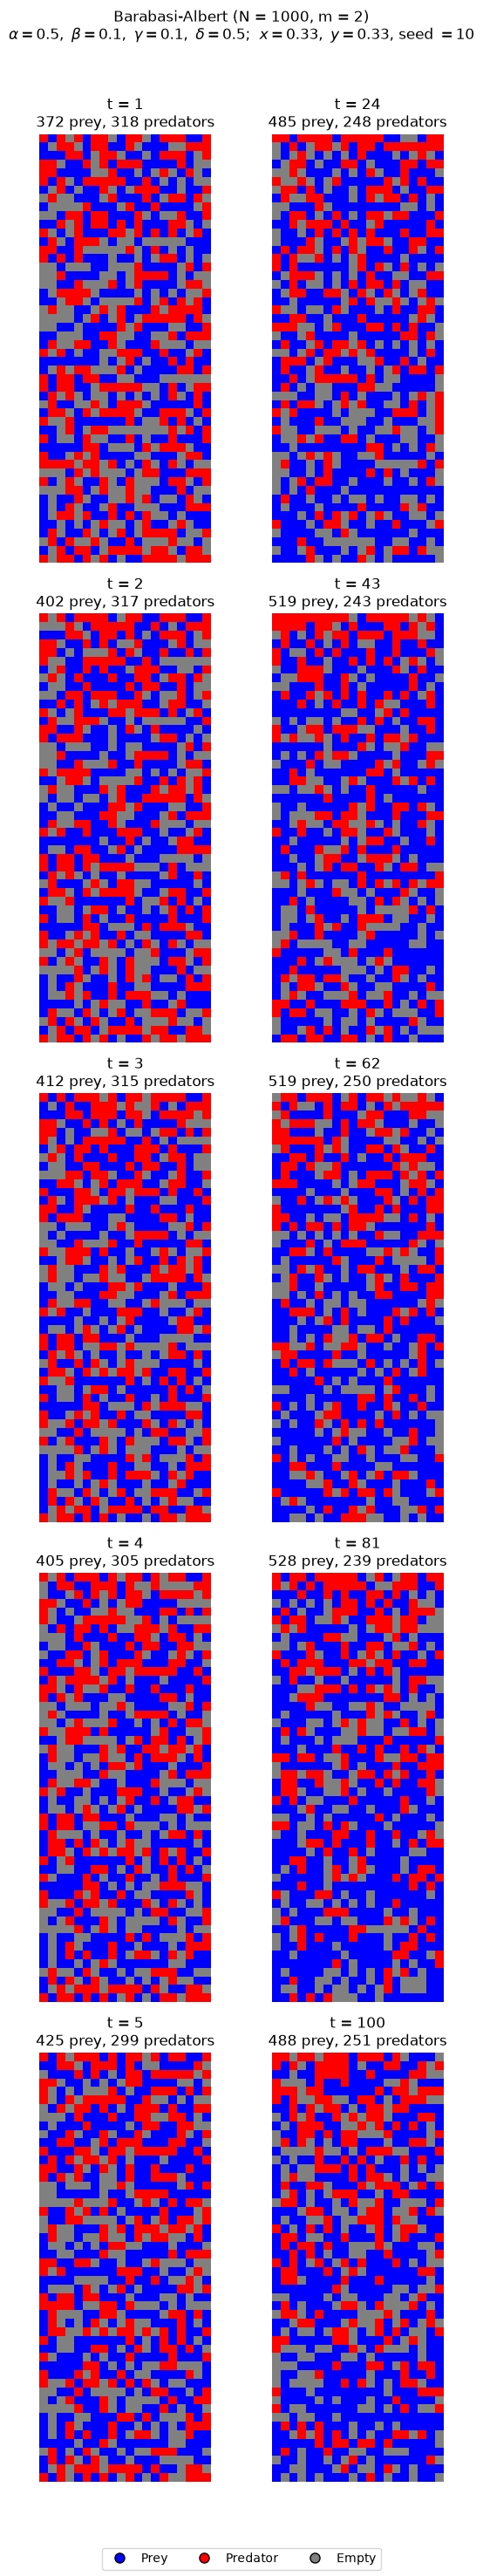

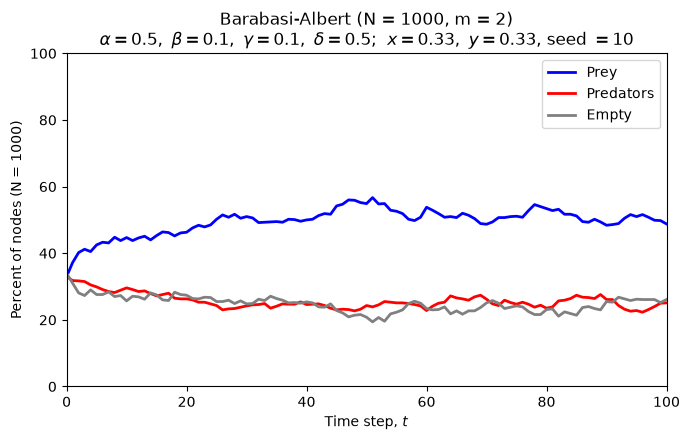

Watts-Strogatz (N = 1000, k = 2, p = 0.05): N = 1000, final prey = 100.0%, final predators = 0.0%, predators extinct at t = 87


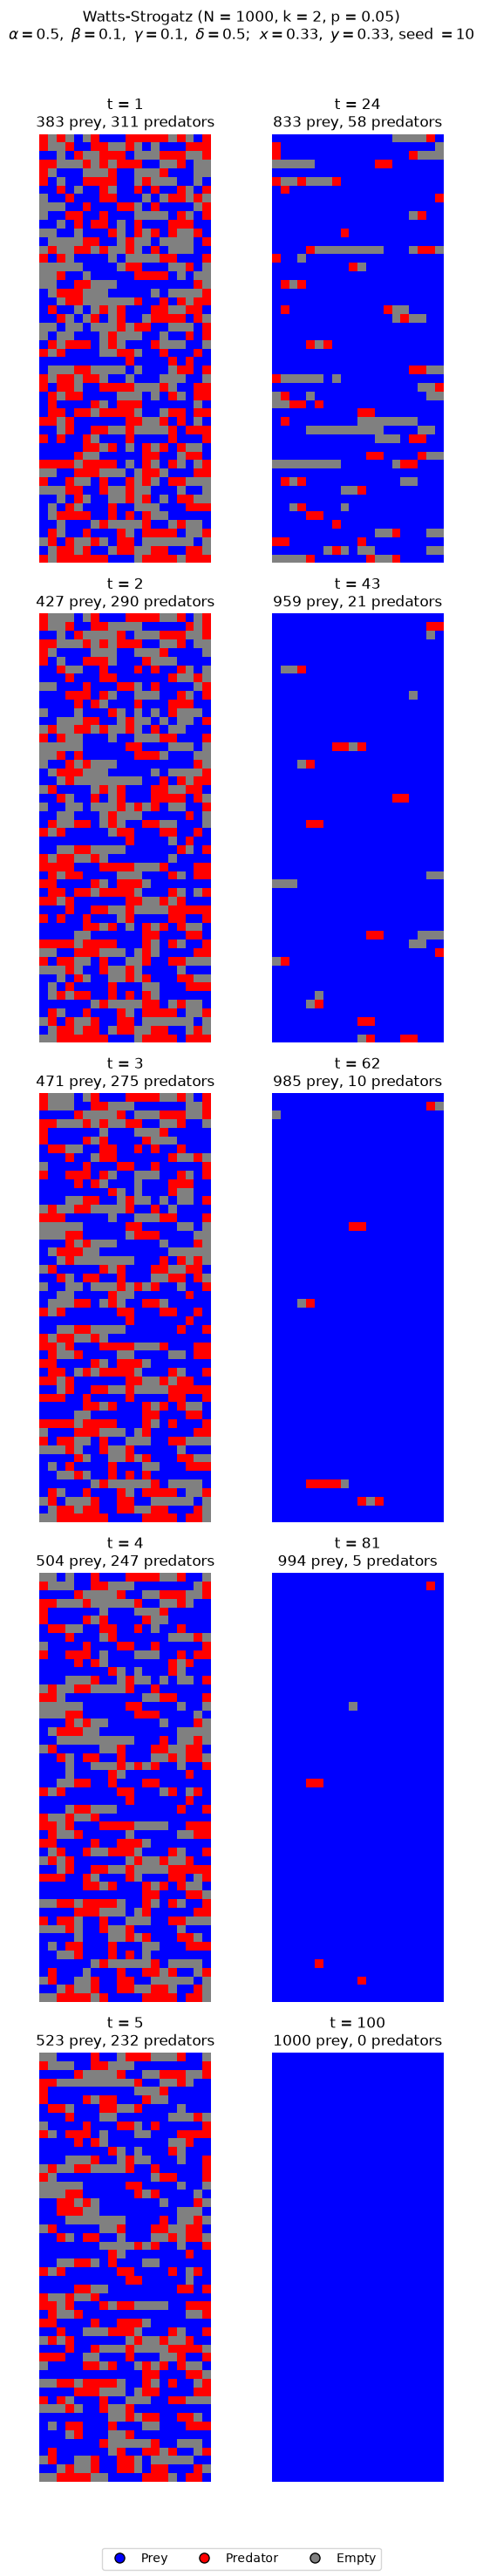

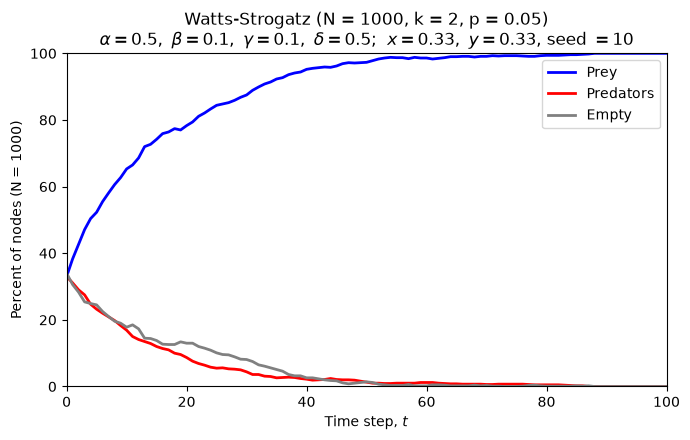

In [12]:
# graphs from the question (seed added to the random ones so the runs are reproducible)
G1 = nx.grid_2d_graph(100, 100)
G2 = nx.gnp_random_graph(1000, 0.05, seed=10)
G3 = nx.barabasi_albert_graph(1000, 2, seed=10)
G4 = nx.watts_strogatz_graph(1000, 2, 0.05, seed=10)

graphs = [
    ("2D grid (100 x 100)", "q2b_grid", G1),
    ("Erdos-Renyi (N = 1000, p = 0.05)", "q2b_erdos_renyi", G2),
    ("Barabasi-Albert (N = 1000, m = 2)", "q2b_barabasi_albert", G3),
    ("Watts-Strogatz (N = 1000, k = 2, p = 0.05)", "q2b_watts_strogatz", G4),
]

# same starting fractions and rates as the 2.a karate club run, for every graph
x, y = 0.33, 0.33
alpha, beta, gamma, delta = 0.5, 0.1, 0.1, 0.5
T, seed = 100, 10

results = {}
for name, filename, G in graphs:
    N = G.number_of_nodes()
    counts = graphLotkeVolterra(G, x, y, alpha, beta, gamma, delta, T, seed=seed)
    results[name] = counts

    # first time step with no predators (None if they survive to T)
    pred_extinct = next((t for t, (n_prey, n_pred) in enumerate(counts) if n_pred == 0), None)
    print(f"{name}: N = {N}, final prey = {counts[-1][0] / N:.1%}, final predators = {counts[-1][1] / N:.1%}, "
          f"predators extinct at t = {pred_extinct}")

    # 10 snapshots above the population plot. The grid is drawn on its lattice positions; the other
    # graphs are drawn as a fixed 20 x 50 array of nodes (node index order) with edges dropped for plotting
    style = "lattice" if G is G1 else "array"
    fig = plot_lv_snapshots(G, x, y, alpha, beta, gamma, delta, T, seed, style=style, n_cols=20, title=name)
    fig.savefig(f"figures/{filename}_snapshots.png", dpi=300)
    plt.show()

    fig = plot_lv_populations(counts, N, alpha, beta, gamma, delta, x, y, seed, title=name)
    fig.savefig(f"figures/{filename}.png", dpi=300)
    plt.show()

mean  median    mode  \
model                                      population                          
2D grid (100 x 100)                        Prey        75.67   75.76   74.87   
                                           Predators   18.38   18.32   17.63   
                                           Empty        5.95    5.95    5.68   
Erdos-Renyi (N = 1000, p = 0.05)           Prey         0.47    0.00    0.00   
                                           Predators    2.41    0.00    0.00   
                                           Empty       97.12  100.00  100.00   
Barabasi-Albert (N = 1000, m = 2)          Prey        51.82   51.75   54.50   
                                           Predators   24.52   24.65   24.70   
                                           Empty       23.65   23.75   23.90   
Watts-Strogatz (N = 1000, k = 2, p = 0.05) Prey        99.73   99.85  100.00   
                                           Predators    0.16    0.10    0.00   
                                           Empty        0.12    0.00    0.00   

                                                         sd  
model                                      population        
2D grid (100 x 100)                        Prey        0.99  
                                           Predators   0.75  
                                           Empty       0.35  
Erdos-Renyi (N = 1000, p = 0.05)           Prey        1.13  
                                           Predators   4.90  
                                           Empty       5.62  
Barabasi-Albert (N = 1000, m = 2)          Prey        3.18  
                                           Predators   1.60  
                                           Empty       2.25  
Watts-Strogatz (N = 1000, k = 2, p = 0.05) Prey        0.34  
                                           Predators   0.20  
                                           Empty       0.21

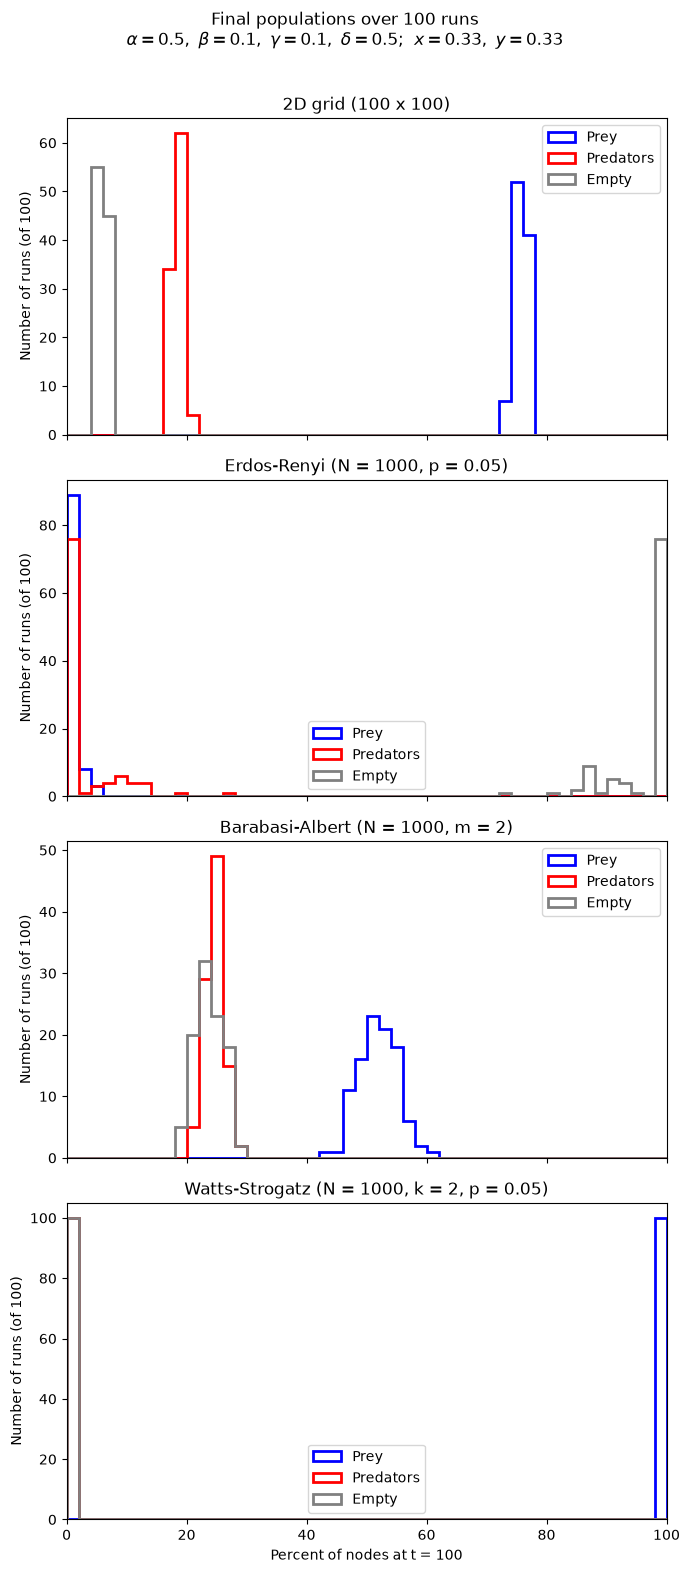

In [ ]:
# 100 runs per graph with different simulation seeds (0-99)
n_runs = 100
rows = []
for name, filename, G in graphs:
    N = G.number_of_nodes()
    for run_seed in range(n_runs):
        n_prey, n_pred = graphLotkeVolterra(G, x, y, alpha, beta, gamma, delta, T, seed=run_seed)[-1]
        rows.append({"model": name, "seed": run_seed,
                     "Prey": n_prey / N * 100,
                     "Predators": n_pred / N * 100,
                     "Empty": (N - n_prey - n_pred) / N * 100})
final = pd.DataFrame(rows)  


def mode_or_nan(values):
    # most common exact final value (smallest one if tied)
    # NaN if every run ended at a different value
    counts = values.value_counts()
    if counts.max() == 1:
        return np.nan
    return counts[counts == counts.max()].index.min()


# summary statistics
summary = (final.melt(id_vars=["model", "seed"], var_name="population", value_name="percent")
           .groupby(["model", "population"], sort=False)["percent"]
           .agg(mean="mean", median="median", mode=mode_or_nan, sd="std")
           .round(2))
# order rows model by model (prey, predators, empty within each model)
summary = summary.reindex(pd.MultiIndex.from_product([[name for name, _, _ in graphs], ["Prey", "Predators", "Empty"]],
                                                     names=["model", "population"]))
display(summary)

# rough histogram curves of the final percentages, one panel per model
bins = np.arange(0, 102, 2)  # 2% wide bins from 0% to 100%
fig, axes = plt.subplots(4, 1, figsize=(7, 16), sharex=True)
for ax, (name, filename, G) in zip(axes, graphs):
    runs = final[final["model"] == name]
    for population, color in [("Prey", "blue"), ("Predators", "red"), ("Empty", "gray")]:
        ax.hist(runs[population], bins=bins, histtype="step", linewidth=2, color=color, label=population)
    ax.set_title(name)
    ax.set_ylabel(f"Number of runs (of {n_runs})")
    ax.set_xlim(0, 100)
    ax.legend()
axes[-1].set_xlabel(f"Percent of nodes at t = {T}")
fig.suptitle("Final populations over 100 runs\n"
             rf"$\alpha={alpha},\ \beta={beta},\ \gamma={gamma},\ \delta={delta}$;  $x={x},\ y={y}$")
fig.tight_layout(rect=(0, 0, 1, 0.97))  
fig.savefig("figures/q2b_final_histograms.png", dpi=300)
plt.show()